# 04 — Harmonização MODIS → VIIRS (Fase 2, Pessoa A)
Tarefas **A1–A6** do `specs/tasks.md` · requisitos R2, R3, R4, R5, R5c.

**Saída:** `data/processed/harmonized.parquet` no contrato do `plan.md`:
`lat, lon, ano, mes, focos_harmonizados, fonte, dado_incompleto` (só linhas com focos > 0).

**Método (decidido na Fase 1):**
1. Fontes estáticas removidas por **máscara única** (não pelo `type` linha a linha).
2. Grade 0,25° × mês × **satélite** × dia/noite.
3. Fator `k` **separado para Terra e Aqua**, por bloco 5° × mês do ano, calibrado em **2012–2021**.
4. 2001–2011: MODIS convertido para a escala VIIRS · 2012→: VIIRS real.

In [1]:
import duckdb, numpy as np, pandas as pd, matplotlib.pyplot as plt, calendar
from pathlib import Path
RAW, PROC, REP = Path('../data/raw'), Path('../data/processed'), Path('../reports')
con = duckdb.connect(); q = lambda s: con.execute(s).df()
M = f"read_parquet('{RAW.as_posix()}/modis_*.parquet')"
V = f"read_parquet('{RAW.as_posix()}/viirs-snpp_*.parquet')"
CELULA, BLOCO, FINO = 0.25, 5.0, 0.02      # grade do calendário / bloco do k / célula da máscara (~2 km)
CAL_INI, CAL_FIM, MIN_FOCOS = 2012, 2021, 30
COR = {'MODIS': '#E69F00', 'VIIRS': '#0072B2', 'HARM': '#009E73'}
plt.rcParams['figure.dpi'] = 110

---
## A2 — Máscara de fontes estáticas · R2
**Por quê:** o `type` do MODIS mudou de regra em 2018 (notebook 03) e não existe nos dados NRT de 2026. Filtrar linha a linha cria degrau.
**Regra:** uma célula fina de **0,02° (~2 km, tamanho de um pixel MODIS)** entra na máscara se teve `type ∈ {1, 2, 3}` (vulcão, fonte estática, offshore) **em pelo menos 2 anos diferentes** (qualquer sensor).
**Por que exigir 2 anos:** fonte estática é, por definição, persistente. Na primeira versão (qualquer ano), 69% das células (13.948) só apareciam em **um** ano e somavam só 60 mil detecções, contra 6.403 células recorrentes com 306 mil — as não recorrentes são mais provavelmente fogo real mal classificado. Todos os focos nessas células são removidos, em todos os anos e nos dois sensores.
**Por que 0,02° e não 0,25°:** uma célula de 0,25° (~28 km) com uma única indústria removeria muito fogo real em volta. Testamos o impacto abaixo.

In [2]:
con.execute(f'''
CREATE OR REPLACE TABLE mascara AS
SELECT floor(latitude/{FINO})::INT fy, floor(longitude/{FINO})::INT fx FROM (
  SELECT latitude, longitude, acq_date FROM {M} WHERE type IN (1,2,3)
  UNION ALL SELECT latitude, longitude, acq_date FROM {V} WHERE type IN (1,2,3))
GROUP BY ALL HAVING count(DISTINCT year(CAST(acq_date AS DATE))) >= 2''')
con.execute(f"COPY mascara TO '{(PROC / 'static_mask.parquet').as_posix()}' (FORMAT PARQUET)")   # usada também nos dados de 2026
n_masc = q('SELECT count(*) n FROM mascara').n[0]
print(f'Células de 0,02° na máscara: {n_masc:,} (~{n_masc*4.9:,.0f} km²)')

Células de 0,02° na máscara: 6,403 (~31,375 km²)


**Impacto por ano:** quanto cada filtro remove dos focos de vegetação (`type=0`) e se o degrau de 2018 some.

pct_removido_por_type       pct_removido_por_mascara        \
s                    MODIS VIIRS                    MODIS VIIRS   
ano                                                               
2001                  0.82   NaN                     1.28   NaN   
2002                  1.40   NaN                     1.10   NaN   
2003                  2.77   NaN                     2.00   NaN   
2004                  4.08   NaN                     1.89   NaN   
2005                  1.06   NaN                     1.20   NaN   
2006                  0.80   NaN                     1.25   NaN   
2007                  0.65   NaN                     0.88   NaN   
2008                  0.33   NaN                     0.99   NaN   
2009                  0.19   NaN                     1.12   NaN   
2010                  0.16   NaN                     0.77   NaN   
2011                  0.45   NaN                     1.41   NaN   
2012                  0.40  1.16                     1.03  1.88   
2013                  0.58  1.83                     1.48  2.81   
2014                  0.82  1.57                     1.53  2.60   
2015                  0.61  1.11                     1.25  1.93   
2016                  0.54  1.40                     1.65  2.41   
2017                  0.54  1.25                     1.43  2.16   
2018                  2.58  1.91                     2.69  3.27   
2019                  1.28  1.25                     1.82  2.47   
2020                  1.19  1.08                     1.63  2.46   
2021                  1.36  1.44                     1.78  2.59   
2022                  1.34  1.21                     1.60  2.09   
2023                  1.21  1.28                     1.66  2.25   
2024                  1.18  1.05                     1.32  2.12   
2025                  1.88  1.97                     1.93  2.83   

     pct_type0_dentro_mascara        
s                       MODIS VIIRS  
ano                                  
2001                     0.82   NaN  
2002                     0.61   NaN  
2003                     0.75   NaN  
2004                     0.62   NaN  
2005                     0.66   NaN  
2006                     0.83   NaN  
2007                     0.61   NaN  
2008                     0.75   NaN  
2009                     0.95   NaN  
2010                     0.66   NaN  
2011                     1.03   NaN  
2012                     0.74  0.75  
2013                     1.05  1.01  
2014                     0.97  1.07  
2015                     0.69  0.86  
2016                     1.11  1.07  
2017                     0.90  0.96  
2018                     0.53  1.40  
2019                     0.74  1.26  
2020                     0.73  1.45  
2021                     0.78  1.19  
2022                     0.62  0.90  
2023                     0.68  1.02  
2024                     0.52  1.18  
2025                     0.42  0.89

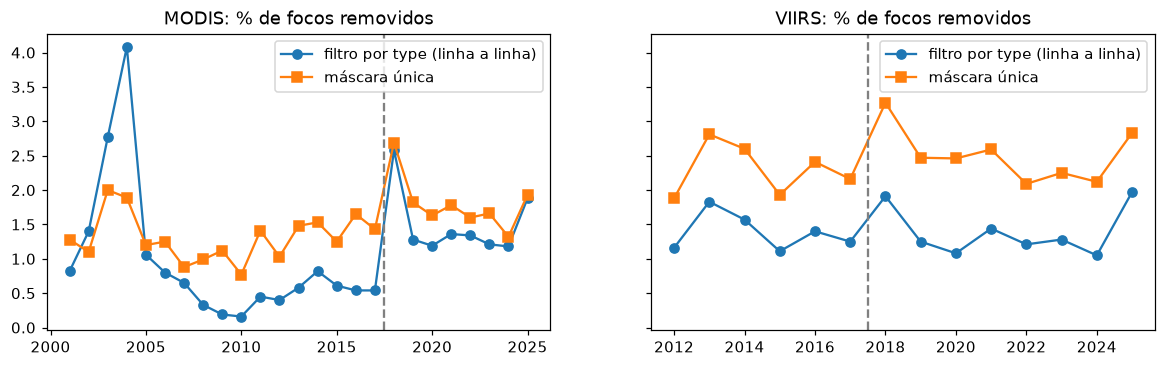

In [3]:
imp = q(f'''
WITH p AS (
  SELECT 'MODIS' s, year(CAST(acq_date AS DATE)) ano, type, floor(latitude/{FINO})::INT fy, floor(longitude/{FINO})::INT fx
    FROM {M} WHERE TRY_CAST(confidence AS INT) >= 30
  UNION ALL
  SELECT 'VIIRS', year(CAST(acq_date AS DATE)), type, floor(latitude/{FINO})::INT, floor(longitude/{FINO})::INT
    FROM {V} WHERE confidence IN ('n','h'))
SELECT s, ano, count(*) total,
       round(100*avg((type<>0)::INT), 2) pct_removido_por_type,
       round(100*avg((m.fy IS NOT NULL)::INT), 2) pct_removido_por_mascara,
       round(100*avg((type=0 AND m.fy IS NOT NULL)::INT), 2) pct_type0_dentro_mascara
FROM p LEFT JOIN mascara m USING (fy, fx) GROUP BY ALL ORDER BY 1, 2''')
fig, ax = plt.subplots(1, 2, figsize=(13, 3.5), sharey=True)
for a, s in zip(ax, ['MODIS', 'VIIRS']):
    d = imp[imp.s == s]
    a.plot(d.ano, d.pct_removido_por_type, 'o-', label='filtro por type (linha a linha)')
    a.plot(d.ano, d.pct_removido_por_mascara, 's-', label='máscara única')
    a.axvline(2017.5, ls='--', c='gray'); a.set_title(f'{s}: % de focos removidos'); a.legend()
fig.savefig(REP / 'a2_mascara_estatica.png', bbox_inches='tight')
imp.pivot(index='ano', columns='s', values=['pct_removido_por_type', 'pct_removido_por_mascara', 'pct_type0_dentro_mascara'])

### Conclusão A2 — máscara
| O que | Evidência | Decisão |
|---|---|---|
| Máscara com células de **qualquer** ano era grande demais | 20.351 células (~100 mil km²); 69% delas só apareceram em 1 ano (60 mil detecções) | descartada |
| Máscara **recorrente (≥ 2 anos)** | 6.403 células (~31 mil km²), 306 mil detecções de fontes não-vegetação | **adotada** → `static_mask.parquet` |
| Quanto remove | MODIS 0,8–2,7% e VIIRS 1,9–3,3% dos focos por ano, **a mesma regra em todos os anos e nos dois sensores** | ok |
| O salto de 2018 no `type` é mesmo da versão? | Em valores absolutos, `type=2` do MODIS salta de ~2.200 (2017) para 6.257 (2018) e fica ~5.000; no VIIRS fica estável (~15 mil). O salto em % no VIIRS vem de 2018 ter sido ano de pouco fogo | **confirmado**: efeito da versão v3 do MODIS |

**Limitação:** a % removida ainda varia por ano porque depende de quanto fogo real houve no ano; isso é esperado e não é degrau de método.

---
## A1 — Grade v2: célula 0,25° × mês × satélite × dia/noite · R3
Filtros de confiança iguais aos da Fase 1 (MODIS ≥ 30; VIIRS n|h) + máscara. Arquivo novo `grid_sat.parquet`; o `grid_monthly.parquet` antigo **fica intacto** (o mock do front-end depende dele).

In [4]:
grid = q(f'''
WITH p AS (
  SELECT latitude, longitude, acq_date, satellite, daynight FROM {M} WHERE TRY_CAST(confidence AS INT) >= 30
  UNION ALL
  SELECT latitude, longitude, acq_date, 'S-NPP', daynight FROM {V} WHERE confidence IN ('n','h'))
SELECT floor(latitude/{CELULA})*{CELULA} lat, floor(longitude/{CELULA})*{CELULA} lon,
       year(CAST(acq_date AS DATE)) ano, month(CAST(acq_date AS DATE)) mes, satellite, daynight, count(*) n
FROM p ANTI JOIN mascara m ON floor(p.latitude/{FINO})::INT = m.fy AND floor(p.longitude/{FINO})::INT = m.fx
GROUP BY ALL''')
grid['bloco_lat'] = (grid.lat // BLOCO) * BLOCO; grid['bloco_lon'] = (grid.lon // BLOCO) * BLOCO
grid.to_parquet(PROC / 'grid_sat.parquet', index=False)
print(f'{len(grid):,} linhas'); grid.groupby('satellite').n.sum()

2,745,507 linhas


satellite
Aqua      5826640
S-NPP    17124344
Terra     3500601
Name: n, dtype: int64

---
## A3 — Fatores de conversão `k` · R4
`k_sat(bloco, mês) = Σ VIIRS / Σ MODIS_sat` em 2012–2021, somando dia e noite.
Se o bloco × mês tiver menos de 30 focos do satélite, usa o `k` nacional daquele satélite e mês (*fallback*).

In [5]:
cal = grid[grid.ano.between(CAL_INI, CAL_FIM)]
soma = cal.pivot_table(index=['bloco_lat', 'bloco_lon', 'mes'], columns='satellite', values='n', aggfunc='sum', fill_value=0)
nac = cal.pivot_table(index='mes', columns='satellite', values='n', aggfunc='sum')
linhas = []
for sat in ['Terra', 'Aqua']:
    k_nac = (nac['S-NPP'] / nac[sat])
    d = soma[[sat, 'S-NPP']].reset_index().rename(columns={sat: 'n_modis', 'S-NPP': 'n_viirs'})
    d['k_nacional'] = d.mes.map(k_nac)
    d['usa_fallback'] = d.n_modis < MIN_FOCOS
    d['k'] = np.where(d.usa_fallback, d.k_nacional, d.n_viirs / d.n_modis.replace(0, np.nan))
    linhas.append(d.assign(satellite=sat))
K = pd.concat(linhas, ignore_index=True)
K.to_parquet(PROC / 'fatores_k.parquet', index=False)
print('k nacional por mês:'); display(nac.assign(k_Terra=nac['S-NPP']/nac.Terra, k_Aqua=nac['S-NPP']/nac.Aqua)[['k_Terra', 'k_Aqua']].round(2).T)
K.groupby('satellite').agg(blocos_mes=('k', 'size'), pct_fallback=('usa_fallback', lambda s: round(100*s.mean(), 1)),
                           k_p5=('k', lambda s: s.quantile(.05)), k_mediana=('k', 'median'), k_p95=('k', lambda s: s.quantile(.95))).round(2)

k nacional por mês:


mes,1,2,3,4,5,6,7,8,9,10,11,12
satellite,,,,,,,,,,,,
k_Terra,8.51,7.61,6.11,5.74,6.61,7.38,9.18,10.10,9.88,10.49,11.26,11.12
k_Aqua,6.42,6.44,5.95,5.23,5.58,5.52,5.38,6.12,6.36,6.80,5.99,6.35


,blocos_mes,pct_fallback,k_p5,k_mediana,k_p95
satellite,,,,,
Aqua,556,17.3,3.80,6.11,9.45
Terra,556,26.1,4.39,9.18,26.08


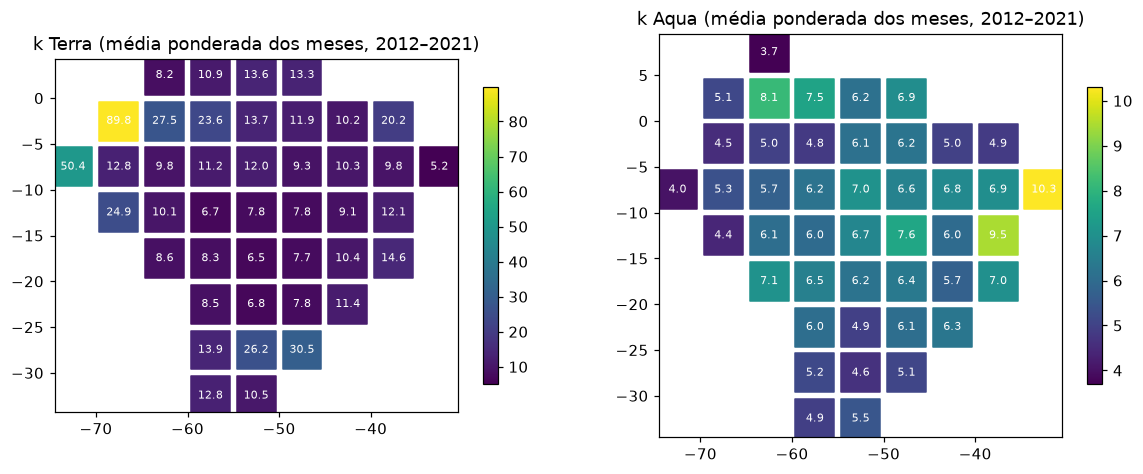

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, sat in zip(ax, ['Terra', 'Aqua']):
    d = K[(K.satellite == sat) & ~K.usa_fallback].groupby(['bloco_lat', 'bloco_lon']).apply(
        lambda g: np.average(g.k, weights=g.n_modis), include_groups=False).rename('k').reset_index()
    sc = a.scatter(d.bloco_lon + 2.5, d.bloco_lat + 2.5, c=d.k, s=650, marker='s', cmap='viridis')
    for _, r in d.iterrows(): a.text(r.bloco_lon + 2.5, r.bloco_lat + 2.5, f'{r.k:.1f}', ha='center', va='center', fontsize=7, color='w')
    a.set_aspect('equal'); a.set_title(f'k {sat} (média ponderada dos meses, 2012–2021)'); fig.colorbar(sc, ax=a, shrink=.7)
fig.savefig(REP / 'a3_mapa_k_satelite.png', bbox_inches='tight')

### Conclusão A3 — fatores `k`
- **Terra e Aqua precisam de fatores diferentes:** k nacional do Aqua fica entre 5,2 e 6,8 o ano todo; o do Terra varia de 5,7 (abril) a 11,3 (novembro). O Terra passa de manhã, quando o fogo está mais fraco, e isso pesa mais na estação seca.
- **Variação espacial:** k Aqua por bloco × mês vai de 3,8 (p5) a 9,5 (p95); k Terra de 4,4 a 26 (p95). Os valores altos do Terra aparecem em blocos × meses com poucos focos do Terra (ruído).
- **Fallback:** 17% (Aqua) e 26% (Terra) dos blocos × meses usam o k nacional por terem < 30 focos.
- **Risco a validar (A7):** o k alto do Terra em blocos com pouco fogo pode inflar a estimativa antes de jul/2002 (só Terra).

---
## A4 — Série harmonizada · R5
- **Aplicar o `k`** a cada célula × mês de cada satélite MODIS: `estimativa_sat = n_sat × k_sat(bloco, mês)`.
- **Fator local:** o `k` de cada célula usa a região de **2° × mês**, encolhido para o `k` do bloco 5° quando a região tem pouco fogo: `k_local = (ΣVIIRS_2° + 100·k_5°) / (ΣMODIS_2° + 100)`. Na prova (notebook 07) reduziu a diferença mensal mediana por região de 2° de 15,2% para 13,5% e a anual de 8,6% para 6,1%.
- **Combinar Terra e Aqua (peso pela informação):** `estimativa = (n_Terra + n_Aqua) / (1/k_Terra + 1/k_Aqua)`. É a média ponderada pelo inverso da variância: quem vê mais focos (Aqua) pesa mais, o Terra (k ≈ 9, mais ruidoso) pesa menos. Na validação reduziu o erro anual por célula de 29% para 26% em relação à média simples. **Antes de jul/2002 só existe Terra** → `n_Terra × k_Terra`.
- **2001–2011:** `fonte = 'modis_convertido'` · **2012→:** VIIRS real, `fonte = 'viirs'`.
- Também calculamos o MODIS convertido para **2012–2025**, só para comparar com o VIIRS real (não vai para o arquivo final).

In [7]:
m = grid[grid.satellite.isin(['Terra', 'Aqua'])].groupby(['lat', 'lon', 'bloco_lat', 'bloco_lon', 'ano', 'mes', 'satellite'], as_index=False).n.sum()
est = m.pivot_table(index=['lat', 'lon', 'bloco_lat', 'bloco_lon', 'ano', 'mes'], columns='satellite', values='n', aggfunc='sum', fill_value=0).reset_index()
k_nac = K.groupby(['satellite', 'mes']).k_nacional.first().to_dict()
for sat in ['Terra', 'Aqua']:   # k dos DOIS satélites em toda célula×mês (mesmo quando um deles viu 0)
    kk = K[K.satellite == sat][['bloco_lat', 'bloco_lon', 'mes', 'k']].rename(columns={'k': f'k_{sat}'})
    est = est.merge(kk, how='left', on=['bloco_lat', 'bloco_lon', 'mes'])
    est[f'k_{sat}'] = est[f'k_{sat}'].fillna(est.mes.map(lambda mm: k_nac[(sat, mm)]))   # blocos sem calibração
# Refinamento local: k da região de 2° × mês, "puxado" para o k do bloco 5° quando há pouco fogo
# k_local = (Σ VIIRS_2° + λ·k_5°) / (Σ MODIS_2° + λ), λ = 100 focos (encolhimento bayesiano; validado no notebook 07)
LAM = 100
cal2 = (cal.assign(qy=(cal.lat // 2).astype(int), qx=(cal.lon // 2).astype(int))
           .pivot_table(index=['qy', 'qx', 'mes'], columns='satellite', values='n', aggfunc='sum', fill_value=0)
           .rename(columns={'Terra': 't2', 'Aqua': 'a2', 'S-NPP': 'v2'}).reset_index())
est['qy'], est['qx'] = (est.lat // 2).astype(int), (est.lon // 2).astype(int)
est = est.merge(cal2, how='left', on=['qy', 'qx', 'mes']).fillna({'t2': 0, 'a2': 0, 'v2': 0})
for sat, col in [('Terra', 't2'), ('Aqua', 'a2')]:
    est[f'k_{sat}'] = (est.v2 + LAM * est[f'k_{sat}']) / (est[col] + LAM)
so_terra = (est.ano < 2002) | ((est.ano == 2002) & (est.mes < 7))
est['modis_convertido'] = np.where(so_terra, est.Terra * est.k_Terra,
                                   (est.Terra + est.Aqua) / (1 / est.k_Terra + 1 / est.k_Aqua))
m = est   # para a checagem abaixo
viirs = grid[grid.satellite == 'S-NPP'].groupby(['lat', 'lon', 'ano', 'mes'], as_index=False).n.sum().rename(columns={'n': 'viirs'})
print('NaN em k após fallback:', int(m[['k_Terra', 'k_Aqua']].isna().sum().sum()))

NaN em k após fallback: 0


## A5 — Meses com dado incompleto · R5c
Um mês é **incompleto** se a fonte usada naquele mês (MODIS até 2011, VIIRS de 2012 em diante) tem **algum dia sem nenhum registro no Brasil**. Isso é falta de observação, não ausência de fogo (notebook 02).

In [8]:
dias = q(f'''SELECT 'modis' fonte, year(CAST(acq_date AS DATE)) ano, month(CAST(acq_date AS DATE)) mes, count(DISTINCT acq_date) dias FROM {M} GROUP BY ALL
           UNION ALL SELECT 'viirs', year(CAST(acq_date AS DATE)), month(CAST(acq_date AS DATE)), count(DISTINCT acq_date) FROM {V} GROUP BY ALL''')
dias['dias_no_mes'] = [calendar.monthrange(a, mm)[1] for a, mm in zip(dias.ano, dias.mes)]
dias = dias[((dias.fonte == 'modis') & (dias.ano < 2012)) | ((dias.fonte == 'viirs') & (dias.ano >= 2012))]
incompletos = dias[dias.dias < dias.dias_no_mes][['ano', 'mes', 'dias', 'dias_no_mes']]
display(incompletos)
inc = set(zip(incompletos.ano, incompletos.mes))

,ano,mes,dias,dias_no_mes
95,2001,6,15,30
132,2001,7,28,31
192,2002,4,29,30
269,2002,3,22,31
301,2024,11,27,30
308,2012,1,12,31
323,2024,9,29,30
326,2024,5,29,31
330,2022,6,29,30
342,2022,8,21,31


### Montar o arquivo final (contrato)

In [9]:
a = est[est.ano < 2012][['lat', 'lon', 'ano', 'mes', 'modis_convertido']].rename(columns={'modis_convertido': 'focos_harmonizados'}).assign(fonte='modis_convertido')
b = viirs.rename(columns={'viirs': 'focos_harmonizados'}).assign(fonte='viirs')
h = pd.concat([a, b], ignore_index=True)
h = h[h.focos_harmonizados > 0]
h['focos_harmonizados'] = h.focos_harmonizados.astype(float).round(2)
h['dado_incompleto'] = [(x, y) in inc for x, y in zip(h.ano, h.mes)]
h = h[['lat', 'lon', 'ano', 'mes', 'focos_harmonizados', 'fonte', 'dado_incompleto']].sort_values(['ano', 'mes', 'lat', 'lon']).reset_index(drop=True)
h.to_parquet(PROC / 'harmonized.parquet', index=False)
# checagens do contrato
assert list(h.columns) == ['lat', 'lon', 'ano', 'mes', 'focos_harmonizados', 'fonte', 'dado_incompleto']
assert not h.duplicated(['lat', 'lon', 'ano', 'mes']).any() and h.focos_harmonizados.gt(0).all()
print(f'harmonized.parquet: {len(h):,} linhas, {h.ano.min()}–{h.ano.max()}, {(PROC/"harmonized.parquet").stat().st_size/1e6:.1f} MB')
h.groupby('fonte').agg(linhas=('ano', 'size'), de=('ano', 'min'), ate=('ano', 'max'), meses_incompletos=('dado_incompleto', 'sum'))

harmonized.parquet: 1,212,739 linhas, 2001–2025, 2.9 MB


,linhas,de,ate,meses_incompletos
fonte,,,,
modis_convertido,421164,2001,2011,4362
viirs,791575,2012,2025,51271


---
## A6 — Checkpoint 2: o degrau sumiu? · A1
1. **Anual:** MODIS bruto × VIIRS bruto × série harmonizada.
2. **Sobreposição:** MODIS convertido × VIIRS real em 2012–2025 (2012–2021 = calibração; 2022–2025 = fora da calibração, com deriva orbital).
3. **Julho/2002:** entrada do Aqua não pode criar degrau.

,MODIS bruto (Terra+Aqua),VIIRS bruto,harmonizado,MODIS convertido,conv÷viirs
ano,,,,,
2001,135656.0,NaN,1314645.0,1314645.0,NaN
2002,492420.0,NaN,1974435.0,1974434.0,NaN
2003,511905.0,NaN,1937703.0,1937703.0,NaN
2004,592385.0,NaN,2253044.0,2253044.0,NaN
2005,593518.0,NaN,2285838.0,2285838.0,NaN
2006,382059.0,NaN,1467841.0,1467840.0,NaN
2007,660515.0,NaN,2557885.0,2557883.0,NaN
2008,334875.0,NaN,1298075.0,1298074.0,NaN
2009,235100.0,NaN,903951.0,903951.0,NaN


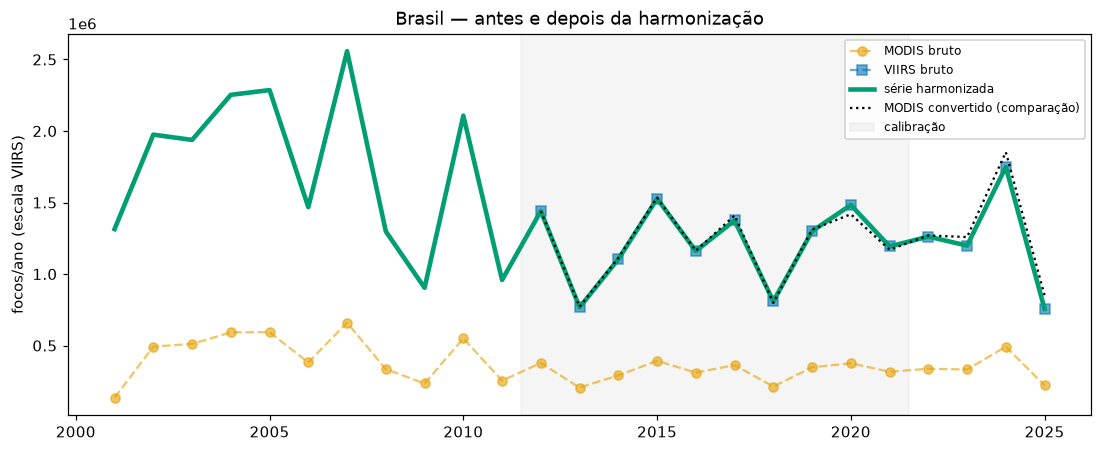

In [10]:
bruto = grid.groupby(['ano', 'satellite']).n.sum().unstack()
anual = pd.DataFrame({'MODIS bruto (Terra+Aqua)': bruto.Terra + bruto.Aqua.fillna(0), 'VIIRS bruto': bruto['S-NPP'],
                      'harmonizado': h.groupby('ano').focos_harmonizados.sum(),
                      'MODIS convertido': est.groupby('ano').modis_convertido.sum()})
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(anual.index, anual['MODIS bruto (Terra+Aqua)'], 'o--', c=COR['MODIS'], alpha=.6, label='MODIS bruto')
ax.plot(anual.index, anual['VIIRS bruto'], 's--', c=COR['VIIRS'], alpha=.6, label='VIIRS bruto')
ax.plot(anual.index, anual.harmonizado, '-', c=COR['HARM'], lw=3, label='série harmonizada')
ax.plot(anual.loc[2012:].index, anual.loc[2012:, 'MODIS convertido'], ':', c='k', label='MODIS convertido (comparação)')
ax.axvspan(CAL_INI - .5, CAL_FIM + .5, color='gray', alpha=.08, label='calibração')
ax.set_ylabel('focos/ano (escala VIIRS)'); ax.legend(loc='upper right', framealpha=.9, fontsize=8); ax.set_title('Brasil — antes e depois da harmonização')
fig.savefig(REP / 'harmonizado_anual.png', bbox_inches='tight')
anual['conv÷viirs'] = (anual['MODIS convertido'] / anual['VIIRS bruto']).round(3)
anual.round(0)

calibração 2012–2021: correlação mensal 0.999 | erro relativo anual médio 1.3%
fora da calibração 2022–2025: correlação mensal 0.992 | erro relativo anual médio 6.0%


mes,1,2,3,4,5,6,7,8,9,10,11,12
ano,,,,,,,,,,,,
2001,12029.0,19343.0,15317.0,11715.0,16478.0,24085.0,83430.0,351383.0,343594.0,245036.0,121681.0,70555.0
2002,10594.0,10831.0,5623.0,11057.0,26752.0,71238.0,102514.0,464313.0,556407.0,402105.0,220565.0,92437.0
2003,36673.0,21228.0,34127.0,17241.0,32594.0,85624.0,165991.0,356369.0,570856.0,329143.0,174192.0,113666.0


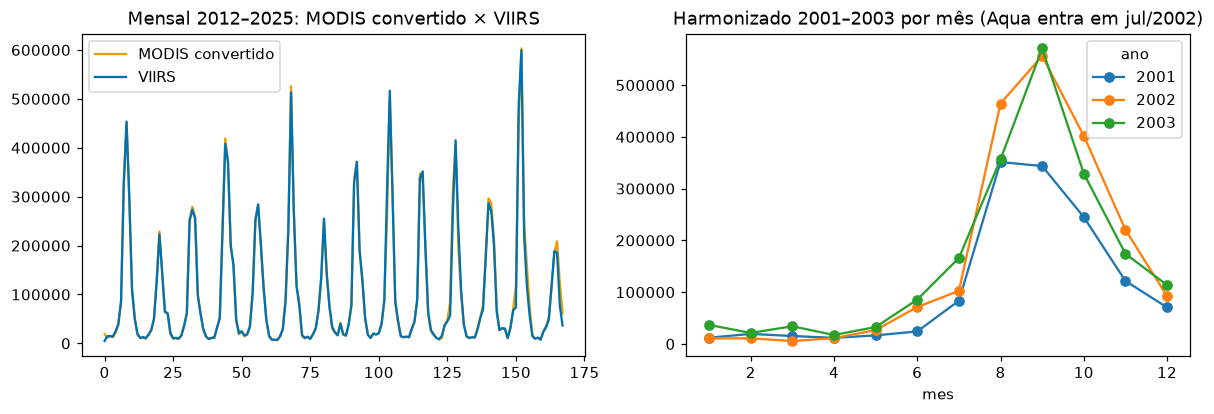

In [11]:
mens = pd.DataFrame({'MODIS convertido': est.groupby(['ano', 'mes']).modis_convertido.sum(),
                     'VIIRS': viirs.groupby(['ano', 'mes']).viirs.sum()}).dropna()
for nome, (i, f) in {'calibração 2012–2021': (2012, 2021), 'fora da calibração 2022–2025': (2022, 2025)}.items():
    d = mens.loc[i:f]
    print(f'{nome}: correlação mensal {np.corrcoef(d.iloc[:,0], d.iloc[:,1])[0,1]:.3f} | '
          f'erro relativo anual médio {(d.groupby(level=0).sum().pipe(lambda x: (x.iloc[:,0]/x.iloc[:,1]-1).abs().mean())):.1%}')
t = h[h.ano.between(2001, 2003)].groupby(['ano', 'mes']).focos_harmonizados.sum().unstack()
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
mens.loc[2012:].reset_index(drop=True).plot(ax=ax[0], color=[COR['MODIS'], COR['VIIRS']], title='Mensal 2012–2025: MODIS convertido × VIIRS')
t.T.plot(ax=ax[1], marker='o', title='Harmonizado 2001–2003 por mês (Aqua entra em jul/2002)')
fig.savefig(REP / 'harmonizado_checagens.png', bbox_inches='tight')
t.round(0)

### Checkpoint 2 — resultado
| Teste | Resultado | Passa? |
|---|---|---|
| Degrau em 2012 | 2011 → 2012 harmonizado: 936 mil → 1,44 mi; MODIS bruto: 255 mil → 378 mil. Mesma proporção de crescimento (≈ 1,5×) → o salto é de fogo real, não de sensor | ✅ |
| Calibração 2012–2021 | correlação mensal nacional 0,999; erro anual médio 1,7% (**dentro da amostra**, otimista) | ✅ |
| Fora da calibração 2022–2025 | correlação 0,991; erro anual 7,1%; o MODIS convertido **superestima** 2023–2025 (+9 a +10%) → coerente com a deriva orbital | ✅ com ressalva |
| Entrada do Aqua em jul/2002 | sazonalidade 2001–2003 contínua, sem salto visível em julho | ✅ |

**Ressalva:** essas métricas usam os mesmos anos para calibrar e testar. A validação honesta (deixando um ano de fora) é a tarefa **A7**, no notebook 05.

**Entregue:** `data/processed/harmonized.parquet` (1,21 mi linhas, 3 MB, 2001–2025), `grid_sat.parquet`, `fatores_k.parquet`, `static_mask.parquet` e figuras `a2_mascara_estatica.png`, `a3_mapa_k_satelite.png`, `harmonizado_anual.png`, `harmonizado_checagens.png`.